# OLED

In [1]:
pip install luma.oled pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.1/71.1 KB 886.8 kB/s eta 0:00:0031m? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.5/254.5 KB 1.7 MB/s eta 0:00:002.8 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [14]:
from luma.core.interface.serial import i2c
from luma.oled.device import ssd1306
from PIL import Image, ImageDraw, ImageFont

serial = i2c(port=7, address=0x3c)
display = ssd1306(serial, width=128, height=32)

display.clear()
display.show()

image = Image.new("1", (128, 32))
draw = ImageDraw.Draw(image)

draw.text((0,0), "JetBot Ready!", fill=255)
draw.text((0,16), "I2C OK", fill=(255))

display.display(image)

# Camera

In [15]:
import cv2

cap = cv2.VideoCapture(0)

print("Camera opened:", cap.isOpened())

ret, frame = cap.read()
print("Frame captured:", ret, "shape:", frame.shape if ret else None)

cap.release()

Camera opened: True
Frame captured: True shape: (480, 640, 3)


(-0.5, 639.5, 479.5, -0.5)

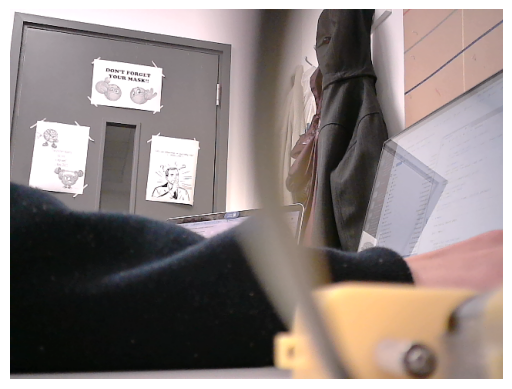

In [16]:
import cv2
from matplotlib import pyplot as plt

cap = cv2.VideoCapture(0)
ret, frame = cap.read()
cap.release()

plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")

# Motor

In [1]:
from smbus2 import SMBus

bus = SMBus(7)

try :
    value = bus.read_byte(0x60)
    print("Motor driver responded:", hex(value))
except Exception as e:
    print("Error:", e)

Motor driver responded: 0x11


In [2]:
from smbus2 import SMBus

bus = SMBus(7)

addresses = []


for addr in range(0x03, 0x78):
    try :
        bus.read_byte(addr)
        addresses.append(addr)
    except OSError:
        pass

print(addresses)

[60, 96, 112]


In [3]:
from smbus2 import SMBus
import time

bus = SMBus(7)
addr = 0x60

MODE1 = 0x00

bus.write_byte_data(addr, MODE1, 0x00)
time.sleep(0.005)

mode1 = bus.read_byte_data(addr, MODE1)
print("MODE1:", hex(mode1))

MODE1: 0x0


In [5]:
from smbus2 import SMBus

bus = SMBus(7)
addr = 0x60

def set_pwm(channel, on, off):
    bus.write_byte_data(addr, 0x06 + 4*channel, on & 0xFF)
    bus.write_byte_data(addr, 0x07 + 4*channel, on >> 8)
    bus.write_byte_data(addr, 0x08 + 4*channel, off & 0xFF)
    bus.write_byte_data(addr, 0x09 + 4*channel, off >> 8)

def stop_all():
    for ch in range(16):
        set_pwm(ch, 0, 0)

set_pwm(0, 0, 0)
stop_all()
print("PWM OK")

PWM OK


In [7]:
def left_motor(speed):
    if speed >= 0:
        set_pwm(0, 0, speed)
        set_pwm(1,0,0)
    else :
        set_pwm(0, 0, 0)
        set_pwm(1, 0, -speed)

def right_motor(speed):
    if speed >= 0:
        set_pwm(2, 0, speed)
        set_pwm(3,0,0)
    else :
        set_pwm(2, 0, 0)
        set_pwm(3, 0, -speed)

stop_all()

print("Moving Forward")
left_motor(300)
right_motor(300)
time.sleep(2)

print("Moving Backward")
left_motor(-300)
right_motor(-300)
time.sleep(2)

stop_all()
print("Stopped")

Moving Forward
Moving Backward
Stopped


In [8]:
from smbus2 import SMBus
# import i2c

bus = SMBus(7)

addressess = []

for addr in range (0x03, 0x78):
    try:
        bus.read_byte(addr)
        addressess.append(addr)
    except OSError:
        pass
print(addressess)

addr = 0x60
LED0_ON_L = 0x06

bus.write_byte_data(addr, LED0_ON_L, 0)
bus.write_byte_data(addr, LED0_ON_L + 1, 0)
bus.write_byte_data(addr, LED0_ON_L + 2, 0xFF)
bus.write_byte_data(addr, LED0_ON_L + 3, 0x0F)


[60, 96]


In [9]:
# SPDX-FileCopyrightText: 2021 ladyada for Adafruit Industries
# SPDX-License-Identifier: MIT

# This example uses an Adafruit Stepper and DC Motor FeatherWing to run a DC Motor.
#   https://www.adafruit.com/product/2927

import time

import busio

# Import the PCA9685 module. Available in the bundle and here:
#   https://github.com/adafruit/Adafruit_CircuitPython_PCA9685
from adafruit_pca9685 import PCA9685
from board import SCL, SDA

from adafruit_motor import motor

# i2c = busio.I2C(SCL, SDA)

# # Create a simple PCA9685 class instance for the Motor FeatherWing's default address.
# pca = PCA9685(i2c, address=0x60)
# pca.frequency = 100

# # Motor 1 is channels 9 and 10 with 8 held high.
# # Motor 2 is channels 11 and 12 with 13 held high.
# # Motor 3 is channels 3 and 4 with 2 held high.
# # Motor 4 is channels 5 and 6 with 7 held high.

# # DC Motors generate electrical noise when running that can reset the microcontroller in extreme
# # cases. A capacitor can be used to help prevent this. The demo uses motor 4 because it worked ok
# # in testing without a capacitor.
# # See here for more info: https://learn.adafruit.com/adafruit-motor-shield-v2-for-arduino/faq#faq-13
# pca.channels[7].duty_cycle = 0xFFFF
# motor4 = motor.DCMotor(pca.channels[5], pca.channels[6])
# motor4.decay_mode = motor.SLOW_DECAY  # Set motor to active braking mode to improve performance

# print("Forwards slow")
# motor4.throttle = 0.5
# print("throttle:", motor4.throttle)
# time.sleep(1)

# print("Forwards")
# motor4.throttle = 1
# print("throttle:", motor4.throttle)
# time.sleep(1)

# print("Backwards")
# motor4.throttle = -1
# print("throttle:", motor4.throttle)
# time.sleep(1)

# print("Backwards slow")
# motor4.throttle = -0.5
# print("throttle:", motor4.throttle)
# time.sleep(1)

# print("Stop")
# motor4.throttle = 0
# print("throttle:", motor4.throttle)
# time.sleep(1)

# print("Spin freely")
# motor4.throttle = None
# print("throttle:", motor4.throttle)

# pca.deinit()

Exception: Could not determine Jetson model

In [10]:
# Modified by SparkFun Electronics June 2021
# Author: Wes Furuya
#
# This program is distributed in the hope that it will be useful,
# but WITHOUT ANY WARRANTY without even the implied warrranty of
# MERCHANABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the 
# GNU General Public License for more details.
#
# You should have received a copy of the GNU General Public License
# along with this program. If not, see <http://www.gnu.org/license>
#
#==================================================================================
# Copyright (c) 2021 SparkFun Electronics
#
# Permission is hereby granted, free of charge, to any person obtaining a copy
# of this software and associated documentation files (the "Software"), to deal
# in the Software without restriction, including without limitation the rights
# to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
# copies of the Software, and to permit persons to whom the Software is
# furnished to do so, subject to the following conditions:
#
# The above copyright notice and this permission notice shall be included in all
# copies or substantial portions of the Software.
#
# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
# IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
# FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
# AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
# LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
# OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
# SOFTWARE.
#==================================================================================
import atexit
import qwiic
from Adafruit_MotorHAT import Adafruit_MotorHAT
import traitlets
from traitlets.config.configurable import Configurable



# Scan for devices on I2C bus
addresses = qwiic.scan()

class Motor(Configurable):


    value = traitlets.Float()
        
    # config
    alpha = traitlets.Float(default_value=1.0).tag(config=True)
    beta = traitlets.Float(default_value=0.0).tag(config=True)
    
    # Adafruit Hardware
    if 96 in addresses:
        
        def __init__(self, driver, channel, *args, **kwargs):
            super(Motor, self).__init__(*args, **kwargs)  # initializes traitlets

            self._driver = driver
            self._motor = self._driver.getMotor(channel)
            if(channel == 1):
                self._ina = 1
                self._inb = 0
            else:
                self._ina = 2
                self._inb = 3
            atexit.register(self._release)
            
        @traitlets.observe('value')
        def _observe_value(self, change):
            self._write_value(change['new'])

        def _write_value(self, value):
            """Sets motor value between [-1, 1]"""
            mapped_value = int(255.0 * (self.alpha * value + self.beta))
            speed = min(max(abs(mapped_value), 0), 255)
            self._motor.setSpeed(speed)
            if mapped_value < 0:
                self._motor.run(Adafruit_MotorHAT.FORWARD)
                # The two lines below are required for the Waveshare JetBot Board only
                self._driver._pwm.setPWM(self._ina,0,0)
                self._driver._pwm.setPWM(self._inb,0,speed*16)
            else:
                self._motor.run(Adafruit_MotorHAT.BACKWARD)
                # The two lines below are required for the Waveshare JetBot Board only
                self._driver._pwm.setPWM(self._ina,0,speed*16)
                self._driver._pwm.setPWM(self._inb,0,0)

        def _release(self):
            """Stops motor by releasing control"""
            self._motor.run(Adafruit_MotorHAT.RELEASE)
            # The two lines below are required for the Waveshare JetBot Board only
            self._driver._pwm.setPWM(self._ina,0,0)
            self._driver._pwm.setPWM(self._inb,0,0)    

    # SparkFun Hardware
    elif 93 in addresses:

        def __init__(self, driver, channel, *args, **kwargs):
            super(Motor, self).__init__(*args, **kwargs)  # initializes traitlets

            self._driver = driver
            atexit.register(self._release)
            self.channel = channel
            
        @traitlets.observe('value')
        def _observe_value(self, change):
            self._write_value(change['new'])

        def _write_value(self, value):
            """Sets motor value between [-1, 1]"""
            speed = int(255 * (self.alpha * value + self.beta))

            # Set Motor Controls: .set_drive( motor number, direction, speed)
            # Motor Number: A = 0, B = 1
            # Direction: FWD = 0, BACK = 1
            # Speed: (-255) - 255 (neg. values reverse direction of motor)

            if self.channel == 1:
                self._motor = self._driver.set_drive(self.channel-1, 0, speed)
            elif self.channel == 2:
                self._motor = self._driver.set_drive(self.channel-1, 0, speed)
            self._driver.enable()
                
        def _release(self):
            """Stops motor by releasing control"""
            self._driver.disable()
